# Analysis: does manager sentiment predict market returns?

The Jiang, Lee, Martin and Zhou design, run on the full-sample manager-sentiment
series in `manager_sentiment_results/manager_sentiment_monthly.parquet`.
The 100 example filings use `manager_sentiment_monthly_sample.parquet` in the same folder.
Covers growth and financial risk
in one pass, since the specification is the same.

1. descriptives and comparison with the published Manager Sentiment Index
2. predictive regressions of cumulative excess market returns on sentiment,
   horizons 1 to 36 months, with and without the Goyal-Welch controls
3. the same over the original 2003-2014 sample period
4. uncertainty interactions: VIX, NVIX, recessions, and growth x financial risk

**Horizons.** `net_cum_return{h}` at month *t* compounds the excess market return
over months *t* through *t+h*: the window spans h+1 months and starts with
the predictor's own month, so `net_cum_return1` is a two-month return covering *t* and *t+1*. Pass
`skip_months=1` to `build_excess_market_returns` for the forward-only variant
(exactly h months, starting at *t+1*); the last section shows both side by side.

**Newey-West lags** scale with the horizon. Consecutive long-horizon returns
overlap almost completely, so a fixed lag length understates the standard errors
at long horizons; `maxlags="horizon"` uses *h* lags for horizon *h*.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parents[1]  # code/analysis -> code -> repo root
sys.path.insert(0, str(REPO_ROOT / "code" / "scripts"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import econometrics as ec
import macro_data as md
import time_aggregation as ta
from prompts import STRATEGIES
from utils import INPUT_DATA_DIR, MANAGER_SENTIMENT_DIR, set_seed, zscore

pd.set_option("display.max_columns", None)
set_seed(42)

MONTH = ta.MONTH_COL
HORIZONS = md.DEFAULT_HORIZONS
print("horizons:", HORIZONS)

horizons: (1, 3, 6, 9, 12, 24, 36)


## Inputs

Market data files are in `input_data/`:

| file | contents |
|---|---|
| `PredictorData2024.xlsx` | Goyal-Welch predictors: index, dividends, earnings, rates, spreads |
| `VIX_History.csv` | daily CBOE VIX |
| `nvix_and_categories_timeseries_mar2016.xlsx` | Manela-Moreira news-implied volatility |
| `SENTIMENT.xlsx` | Baker-Wurgler workbook, used for the recession flag |
| `JLMZ_MS_Index2017.xlsx` | published Manager Sentiment Index |

Filing length is separate from these monthly inputs. `sentiment_extraction_results/filing_word_counts.parquet`
holds `N_Words` and `N_Unique_Words` for every filing in `sent_growth_fin_risk_10k_10q.parquet`.
The regressions below do not use it.

In [2]:
PATHS = {
    "goyal_welch": INPUT_DATA_DIR / "PredictorData2024.xlsx",
    "vix": INPUT_DATA_DIR / "VIX_History.csv",
    "nvix": INPUT_DATA_DIR / "nvix_and_categories_timeseries_mar2016.xlsx",
    "recession": INPUT_DATA_DIR / "SENTIMENT.xlsx",
    "msi": INPUT_DATA_DIR / "JLMZ_MS_Index2017.xlsx",
}
SERIES_PATH = MANAGER_SENTIMENT_DIR / "manager_sentiment_monthly.parquet"

for name, path in {**PATHS, "manager sentiment": SERIES_PATH}.items():
    print(f"  {name:18s} {path.name}")

  goyal_welch        PredictorData2024.xlsx
  vix                VIX_History.csv
  nvix               nvix_and_categories_timeseries_mar2016.xlsx
  recession          SENTIMENT.xlsx
  msi                JLMZ_MS_Index2017.xlsx
  manager sentiment  manager_sentiment_monthly.parquet


In [3]:
sentiment = pd.read_parquet(SERIES_PATH)
sentiment[MONTH] = pd.to_datetime(sentiment[MONTH])

# Default predictor is the normalized 4-month average from build_manager_sentiment.
# "" is the raw monthly mean. "_ma4" and "_hp1s" exist only if those smoothers
# were used. "_hp" uses later months.
SMOOTHING_SUFFIX = "_ma4_norm"  # "_ma4_norm" | "" | "_ma4" | "_hp1s"

MEASURES = [c for c in sentiment.columns
            if c.startswith(("polarity_", "positive_", "negative_"))
            and not c.endswith(("_ma4", "_ma4_norm", "_hp", "_hp1s"))]
PREDICTORS = {m: f"{m}{SMOOTHING_SUFFIX}" for m in MEASURES}

print("measures  :", MEASURES)
print("predictors:", list(PREDICTORS.values()))
print("span      :", sentiment[MONTH].min().date(), "to", sentiment[MONTH].max().date())

measures  : ['polarity_financial_risk', 'polarity_growth_llama']
predictors: ['polarity_financial_risk_ma4_norm', 'polarity_growth_llama_ma4_norm']
span      : 2003-01-01 to 2023-12-01


### Sign convention

Taken from the strategy definitions instead of being applied by hand. For
`financial_risk` the "positive" verbalizer words are *low-risk* words
("manageable", "negligible"), so a higher polarity already means *less* perceived
risk, i.e. good news -- the same direction as growth sentiment. No flip needed.

In [4]:
STRATEGY_ALIASES = {"growth_llama": "growth", "growth_MB": "growth"}

for measure in MEASURES:
    name = measure
    for prefix in ("polarity_", "positive_", "negative_"):
        if name.startswith(prefix):
            name = name[len(prefix):]
            break
    strategy = STRATEGIES.get(STRATEGY_ALIASES.get(name, name))
    if strategy is None:
        print(f"  {measure}: no matching strategy, check the sign yourself")
        continue
    direction = "higher = good news" if strategy.higher_is_good else "higher = bad news"
    print(f"  {measure}: {direction}")
    print(f"      {strategy.description}")

  polarity_financial_risk: higher = good news
      Perceived level of financial risk; higher polarity = lower risk.
  polarity_growth_llama: higher = good news
      Management's outlook on future growth prospects.


## Market data and horizon returns

In [5]:
SAMPLE_START = "200212"  # one month of lead-in so the first excess return is defined

gw = md.load_goyal_welch(PATHS["goyal_welch"], start=SAMPLE_START)
market = md.build_excess_market_returns(gw, horizons=HORIZONS, skip_months=0)

CONTROLS = list(md.GOYAL_WELCH_CONTROLS)
print("controls:", CONTROLS)
market[["excess_return", *md.return_columns(HORIZONS)]].describe().round(4)

/opt/anaconda3/lib/python3.13/site-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")
00:05:22 | INFO    | macro_data | loaded Goyal-Welch: 265 month(s), 2002-12-01 to 2024-12-01
00:05:22 | INFO    | macro_data | built net_cum_return for horizons [1, 3, 6, 9, 12, 24, 36]: window t+0 .. t+h (includes the predictor's own month, h+1 months wide)


controls: ['log_DP', 'log_EP', 'svar', 'bm', 'ntis', 'tbl', 'lty', 'ltr', 'tms', 'dfy', 'dfr', 'infl']


,excess_return,net_cum_return1,net_cum_return3,net_cum_return6,net_cum_return9,net_cum_return12,net_cum_return24,net_cum_return36
count,264.0000,263.0000,261.0000,258.0000,255.0000,252.0000,240.0000,228.0000
mean,0.0069,0.0141,0.0284,0.0495,0.0704,0.0901,0.1658,0.2476
std,0.0422,0.0598,0.0838,0.1140,0.1413,0.1616,0.2251,0.2662
min,-0.1702,-0.2468,-0.2980,-0.4225,-0.4745,-0.4743,-0.5176,-0.4832
25%,-0.0173,-0.0121,-0.0081,-0.0026,0.0076,0.0222,0.0790,0.1693
50%,0.0110,0.0210,0.0353,0.0586,0.0750,0.1052,0.1750,0.2862
75%,0.0319,0.0510,0.0741,0.1170,0.1438,0.1834,0.3199,0.4120
max,0.1268,0.1870,0.2653,0.4371,0.5158,0.6165,0.7999,0.9119


In [6]:
# Sanity check on the horizon convention: net_cum_return1 at t must compound
# month t and month t+1.
check = market[[MONTH, "excess_return", "net_cum_return1"]].head(6).copy()
check["next_month_return"] = market["excess_return"].shift(-1)
check["t_and_t+1_compounded"] = (1 + check["excess_return"]) * (1 + check["next_month_return"]) - 1
print(check.round(6).to_string(index=False))

expected = (1 + market["excess_return"]) * (1 + market["excess_return"].shift(-1)) - 1
both = market["net_cum_return1"].notna() & expected.notna()
print("\nnet_cum_return1 == (1+r_t)(1+r_t+1)-1:",
      np.allclose(market.loc[both, "net_cum_return1"], expected[both]))

year_month  excess_return  net_cum_return1  next_month_return  t_and_t+1_compounded
2002-12-01            NaN              NaN          -0.028415                   NaN
2003-01-01      -0.028415        -0.045810          -0.017904             -0.045810
2003-02-01      -0.017904        -0.010678           0.007358             -0.010678
2003-03-01       0.007358         0.087991           0.080044              0.087991
2003-04-01       0.080044         0.134045           0.049999              0.134045
2003-05-01       0.049999         0.060848           0.010333              0.060848

net_cum_return1 == (1+r_t)(1+r_t+1)-1: True


In [7]:
msi = md.load_msi(PATHS["msi"])
vix = md.load_vix(PATHS["vix"])
nvix = md.load_nvix(PATHS["nvix"])
recession = md.load_recession(PATHS["recession"])

data = md.merge_monthly(market, sentiment, msi, vix, nvix, recession)
print()
print("merged shape:", data.shape)

00:05:22 | INFO    | macro_data | merged ['n_obs', 'polarity_financial_risk', 'polarity_growth_llama', 'polarity_financial_risk_ma4_norm', 'polarity_growth_llama_ma4_norm']: 252 of 265 month(s) matched
00:05:22 | INFO    | macro_data | merged ['msi']: 180 of 265 month(s) matched
00:05:22 | INFO    | macro_data | merged ['vix']: 265 of 265 month(s) matched
00:05:22 | INFO    | macro_data | merged ['nvix']: 160 of 265 month(s) matched
00:05:22 | INFO    | macro_data | merged ['recession']: 253 of 265 month(s) matched



merged shape: (265, 43)


In [8]:
# Standardize predictors and moderators so coefficients are per standard
# deviation and comparable across measures.
TO_STANDARDIZE = [*PREDICTORS.values(), "msi", "vix", "nvix"]

for col in TO_STANDARDIZE:
    if col in data.columns:
        data[f"{col}_z"] = zscore(data[col])

SENTIMENT_Z = {m: f"{p}_z" for m, p in PREDICTORS.items()}
MSI_Z, VIX_Z, NVIX_Z = "msi_z", "vix_z", "nvix_z"

data[[*SENTIMENT_Z.values(), MSI_Z, VIX_Z, NVIX_Z, "recession"]].describe().round(3)

,polarity_financial_risk_ma4_norm_z,polarity_growth_llama_ma4_norm_z,msi_z,vix_z,nvix_z,recession
count,249.000,249.000,180.000,265.000,160.000,253.000
mean,0.000,-0.000,-0.000,0.000,-0.000,0.087
std,1.002,1.002,1.003,1.002,1.003,0.282
min,-4.565,-3.155,-4.146,-1.113,-1.587,0.000
25%,-0.472,-0.453,-0.422,-0.642,-0.849,0.000
50%,0.294,-0.104,0.143,-0.231,0.075,0.000
75%,0.607,0.563,0.710,0.367,0.579,0.000
max,1.521,2.202,1.966,5.376,4.278,1.000


## Descriptives

How the measures relate to each other and to the published index. `n=` in each
cell is the pairwise sample -- the measures rarely cover the same months.

In [9]:
ec.correlation_with_pvalues(data, [*SENTIMENT_Z.values(), MSI_Z, VIX_Z, NVIX_Z])

,polarity_financial_risk_ma4_norm_z,polarity_growth_llama_ma4_norm_z,msi_z,vix_z,nvix_z
polarity_financial_risk_ma4_norm_z,1.00,0.60*** (n=249),0.05 (n=177),-0.43*** (n=249),-0.53*** (n=156)
polarity_growth_llama_ma4_norm_z,0.60*** (n=249),1.00,0.40*** (n=177),-0.34*** (n=249),-0.57*** (n=156)
msi_z,0.05 (n=177),0.40*** (n=177),1.00,-0.02 (n=180),-0.05 (n=159)
vix_z,-0.43*** (n=249),-0.34*** (n=249),-0.02 (n=180),1.00,0.76*** (n=160)
nvix_z,-0.53*** (n=156),-0.57*** (n=156),-0.05 (n=159),0.76*** (n=160),1.00


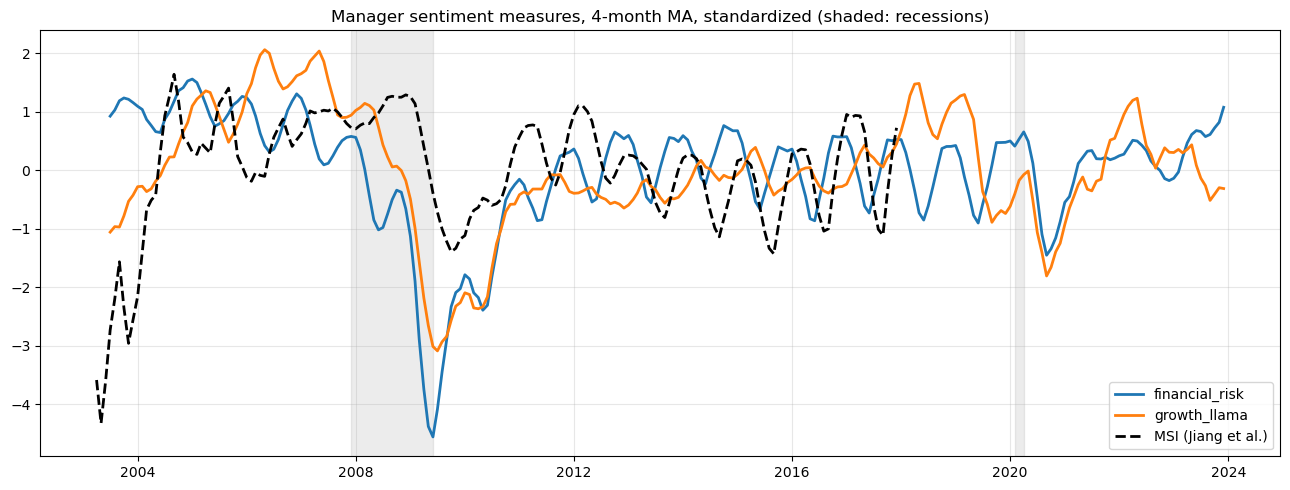

In [10]:
fig, ax = plt.subplots(figsize=(13, 5))

smoothed = data.set_index(MONTH)
for measure, predictor in SENTIMENT_Z.items():
    label = measure
    for prefix in ("polarity_", "positive_", "negative_"):
        if label.startswith(prefix):
            label = label[len(prefix):]
            break
    ax.plot(smoothed.index, zscore(smoothed[predictor].rolling(4).mean()),
            linewidth=2, label=label)
ax.plot(smoothed.index, zscore(smoothed[MSI_Z].rolling(4).mean()),
        linewidth=2, linestyle="--", color="black", label="MSI (Jiang et al.)")

# shade each contiguous recession block
in_recession = smoothed["recession"].fillna(0).astype(bool)
blocks = (in_recession != in_recession.shift()).cumsum()[in_recession]
for _, months in smoothed.index.to_series()[in_recession].groupby(blocks):
    ax.axvspan(months.min(), months.max(), color="grey", alpha=0.15)

ax.set_title("Manager sentiment measures, 4-month MA, standardized (shaded: recessions)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## Predictive regressions

One regression per horizon: `net_cum_return{h} ~ sentiment_z`, Newey-West with
*h* lags. Read `nobs` next to every coefficient -- the long horizons lose the end
of the sample, and the measures do not share a sample.

In [11]:
# Benchmark: the published Manager Sentiment Index over the same months.
_, msi_table = ec.predictive_regression(data, MSI_Z, HORIZONS)
msi_table

,coef,t,pval,r2_adj,nobs,maxlags
net_cum_return1,-0.0144***,-3.072,0.0021,5.683,180,1
net_cum_return3,-0.0278***,-3.191,0.0014,10.443,180,3
net_cum_return6,-0.0411***,-2.832,0.0046,11.825,180,6
net_cum_return9,-0.0512***,-2.692,0.0071,12.692,180,9
net_cum_return12,-0.0556**,-2.454,0.0141,11.746,180,12
net_cum_return24,-0.0662,-1.637,0.1017,7.726,180,24
net_cum_return36,-0.0726,-1.606,0.1082,6.17,180,36


In [12]:
models = {}
for measure, predictor in SENTIMENT_Z.items():
    models[measure], table = ec.predictive_regression(data, predictor, HORIZONS)
    print(f"\n{measure}  ({predictor})")
    print(table.to_string())


polarity_financial_risk  (polarity_financial_risk_ma4_norm_z)
                        coef      t    pval  r2_adj nobs maxlags
net_cum_return1      -0.0042 -0.702  0.4827   0.078  249       1
net_cum_return3      -0.0078 -0.723  0.4694   0.437  249       3
net_cum_return6      -0.0171 -1.037  0.2999   1.817  249       6
net_cum_return9      -0.0241 -1.367  0.1717   2.534  249       9
net_cum_return12   -0.0314** -2.113  0.0346   3.436  249      12
net_cum_return24   -0.067*** -3.036  0.0024   8.682  237      24
net_cum_return36  -0.1042*** -3.092   0.002  15.968  225      36

polarity_growth_llama  (polarity_growth_llama_ma4_norm_z)
                        coef      t    pval  r2_adj nobs maxlags
net_cum_return1   -0.0138*** -3.147  0.0017   4.804  249       1
net_cum_return3    -0.025***   -3.4  0.0007    8.34  249       3
net_cum_return6   -0.0456*** -3.631  0.0003  15.498  249       6
net_cum_return9    -0.065*** -3.696  0.0002  20.921  249       9
net_cum_return12  -0.0819*** -3.7

In [13]:
# Side by side, including the published index.
ec.compare_measures(data, [MSI_Z, *SENTIMENT_Z.values()], HORIZONS)

coef      t  \
msi_z                              net_cum_return1   -0.0144*** -3.072   
                                   net_cum_return3   -0.0278*** -3.191   
                                   net_cum_return6   -0.0411*** -2.832   
                                   net_cum_return9   -0.0512*** -2.692   
                                   net_cum_return12   -0.0556** -2.454   
                                   net_cum_return24     -0.0662 -1.637   
                                   net_cum_return36     -0.0726 -1.606   
polarity_financial_risk_ma4_norm_z net_cum_return1      -0.0042 -0.702   
                                   net_cum_return3      -0.0078 -0.723   
                                   net_cum_return6      -0.0171 -1.037   
                                   net_cum_return9      -0.0241 -1.367   
                                   net_cum_return12   -0.0314** -2.113   
                                   net_cum_return24   -0.067*** -3.036   
                                   net_cum_return36  -0.1042*** -3.092   
polarity_growth_llama_ma4_norm_z   net_cum_return1   -0.0138*** -3.147   
                                   net_cum_return3    -0.025***   -3.4   
                                   net_cum_return6   -0.0456*** -3.631   
                                   net_cum_return9    -0.065*** -3.696   
                                   net_cum_return12  -0.0819*** -3.742   
                                   net_cum_return24  -0.1246*** -3.166   
                                   net_cum_return36   -0.1493** -2.415   

                                                       pval  r2_adj nobs  \
msi_z                              net_cum_return1   0.0021   5.683  180   
                                   net_cum_return3   0.0014  10.443  180   
                                   net_cum_return6   0.0046  11.825  180   
                                   net_cum_return9   0.0071  12.692  180   
                                   net_cum_return12  0.0141  11.746  180   
                                   net_cum_return24  0.1017   7.726  180   
                                   net_cum_return36  0.1082    6.17  180   
polarity_financial_risk_ma4_norm_z net_cum_return1   0.4827   0.078  249   
                                   net_cum_return3   0.4694   0.437  249   
                                   net_cum_return6   0.2999   1.817  249   
                                   net_cum_return9   0.1717   2.534  249   
                                   net_cum_return12  0.0346   3.436  249   
                                   net_cum_return24  0.0024   8.682  237   
                                   net_cum_return36   0.002  15.968  225   
polarity_growth_llama_ma4_norm_z   net_cum_return1   0.0017   4.804  249   
                                   net_cum_return3   0.0007    8.34  249   
                                   net_cum_return6   0.0003  15.498  249   
                                   net_cum_return9   0.0002  20.921  249   
                                   net_cum_return12  0.0002  25.734  249   
                                   net_cum_return24  0.0015   31.63  237   
                                   net_cum_return36  0.0157  33.063  225   

                                                    maxlags  
msi_z                              net_cum_return1        1  
                                   net_cum_return3        3  
                                   net_cum_return6        6  
                                   net_cum_return9        9  
                                   net_cum_return12      12  
                                   net_cum_return24      24  
                                   net_cum_return36      36  
polarity_financial_risk_ma4_norm_z net_cum_return1        1  
                                   net_cum_return3        3  
                                   net_cum_return6        6  
                                   net_cum_return9        9  
             

In [14]:
# With the Goyal-Welch controls.
for measure, predictor in SENTIMENT_Z.items():
    _, table = ec.predictive_regression(data, predictor, HORIZONS, controls=CONTROLS)
    print(f"\n{measure} + {len(CONTROLS)} controls")
    print(table.to_string())


polarity_financial_risk + 12 controls
                      coef      t    pval  r2_adj nobs maxlags
net_cum_return1     0.0021  0.304   0.761   24.46  249       1
net_cum_return3      0.015  1.517  0.1291  30.206  249       3
net_cum_return6   0.0261**  2.072  0.0382  44.232  249       6
net_cum_return9     0.028*  1.791  0.0734  45.673  249       9
net_cum_return12    0.0203  1.088  0.2768  42.901  249      12
net_cum_return24    0.0221  0.785  0.4325  49.244  237      24
net_cum_return36   -0.0334  -1.22  0.2224  62.604  225      36

polarity_growth_llama + 12 controls
                        coef      t    pval  r2_adj nobs maxlags
net_cum_return1      -0.0101 -1.551  0.1209  25.619  249       1
net_cum_return3      -0.0122 -1.084  0.2784  29.835  249       3
net_cum_return6      -0.0231  -1.39  0.1645  43.879  249       6
net_cum_return9    -0.0455** -2.284  0.0224  48.562  249       9
net_cum_return12  -0.0702*** -3.584  0.0003  50.482  249      12
net_cum_return24   -0.0712** -

### Original sample period

January 2003 to December 2014, the window Jiang et al. report, so the numbers
can be put next to the published ones.

In [15]:
JIANG_PERIOD = ("2003-01-01", "2014-12-31")
jiang = data[data[MONTH].between(*JIANG_PERIOD)].reset_index(drop=True)
print(f"{len(jiang)} month(s) in the original window")

ec.compare_measures(jiang, [MSI_Z, *SENTIMENT_Z.values()], HORIZONS)

144 month(s) in the original window


coef      t  \
msi_z                              net_cum_return1   -0.0184*** -3.701   
                                   net_cum_return3   -0.0349*** -3.706   
                                   net_cum_return6   -0.0492*** -3.026   
                                   net_cum_return9   -0.0631***  -2.99   
                                   net_cum_return12    -0.065** -2.567   
                                   net_cum_return24    -0.0744* -1.687   
                                   net_cum_return36    -0.0809* -1.686   
polarity_financial_risk_ma4_norm_z net_cum_return1      -0.0036 -0.522   
                                   net_cum_return3      -0.0076 -0.608   
                                   net_cum_return6       -0.016 -0.814   
                                   net_cum_return9      -0.0255 -1.253   
                                   net_cum_return12   -0.0353** -2.156   
                                   net_cum_return24  -0.0795*** -3.413   
                                   net_cum_return36  -0.1187*** -3.923   
polarity_growth_llama_ma4_norm_z   net_cum_return1     -0.012**  -2.36   
                                   net_cum_return3   -0.0242*** -2.719   
                                   net_cum_return6   -0.0429*** -2.828   
                                   net_cum_return9   -0.0624*** -2.968   
                                   net_cum_return12  -0.0773*** -2.952   
                                   net_cum_return24   -0.149*** -3.568   
                                   net_cum_return36  -0.2053*** -4.993   

                                                       pval  r2_adj nobs  \
msi_z                              net_cum_return1   0.0002   9.079  144   
                                   net_cum_return3   0.0002  15.392  144   
                                   net_cum_return6   0.0025   15.59  144   
                                   net_cum_return9   0.0028  17.681  144   
                                   net_cum_return12  0.0103  14.847  144   
                                   net_cum_return24  0.0915   8.831  144   
                                   net_cum_return36  0.0918   6.883  144   
polarity_financial_risk_ma4_norm_z net_cum_return1   0.6017  -0.206  141   
                                   net_cum_return3   0.5434   0.329  141   
                                   net_cum_return6   0.4155   1.626  141   
                                   net_cum_return9   0.2101   3.449  141   
                                   net_cum_return12  0.0311   5.725  141   
                                   net_cum_return24  0.0006  14.156  141   
                                   net_cum_return36  0.0001  21.522  141   
polarity_growth_llama_ma4_norm_z   net_cum_return1   0.0183   4.511  141   
                                   net_cum_return3   0.0065   8.961  141   
                                   net_cum_return6   0.0047  14.698  141   
                                   net_cum_return9    0.003  22.107  141   
                                   net_cum_return12  0.0032  27.398  141   
                                   net_cum_return24  0.0004  46.983  141   
                                   net_cum_return36     0.0  59.979  141   

                                                    maxlags  
msi_z                              net_cum_return1        1  
                                   net_cum_return3        3  
                                   net_cum_return6        6  
                                   net_cum_return9        9  
                                   net_cum_return12      12  
                                   net_cum_return24      24  
                                   net_cum_return36      36  
polarity_financial_risk_ma4_norm_z net_cum_return1        1  
                                   net_cum_return3        3  
                                   net_cum_return6        6  
                                   net_cum_return9        9  
             

## Uncertainty interactions

`return ~ sentiment + uncertainty + sentiment x uncertainty`. The table reports
the interaction coefficient: whether sentiment predicts returns differently when
uncertainty is high.

In [16]:
MODERATORS = {"VIX": VIX_Z, "NVIX": NVIX_Z, "recession": "recession"}

interaction_models = {}
for measure, predictor in SENTIMENT_Z.items():
    for label, moderator in MODERATORS.items():
        if data[moderator].notna().sum() < 24:
            print(f"skipping {measure} x {label}: only {data[moderator].notna().sum()} month(s)")
            continue
        term = md.add_interaction(data, predictor, moderator)
        fitted, table = ec.interaction_regression(
            data, predictor, moderator, HORIZONS, interaction=term
        )
        interaction_models[(measure, label)] = fitted
        print(f"\n{measure} x {label}  (coefficient on the interaction)")
        print(table.to_string())


polarity_financial_risk x VIX  (coefficient on the interaction)
                       coef      t    pval  r2_adj nobs maxlags
net_cum_return1     -0.0044  -0.88  0.3787   4.603  249       1
net_cum_return3    -0.0112*   -1.7   0.089   4.294  249       3
net_cum_return6   -0.0214**  -2.54  0.0111   6.935  249       6
net_cum_return9    -0.024** -2.061  0.0393   7.053  249       9
net_cum_return12    -0.0222 -1.594  0.1109   6.616  249      12
net_cum_return24    -0.0069 -0.335  0.7377  10.296  237      24
net_cum_return36     0.0224  0.906   0.365  18.212  225      36

polarity_financial_risk x NVIX  (coefficient on the interaction)
                        coef      t    pval  r2_adj nobs maxlags
net_cum_return1       0.0006  0.088  0.9301   8.328  156       1
net_cum_return3      -0.0082 -0.926  0.3545     4.3  156       3
net_cum_return6     -0.026** -2.428  0.0152   6.294  156       6
net_cum_return9   -0.0353*** -2.666  0.0077  10.155  156       9
net_cum_return12   -0.0346** -2.

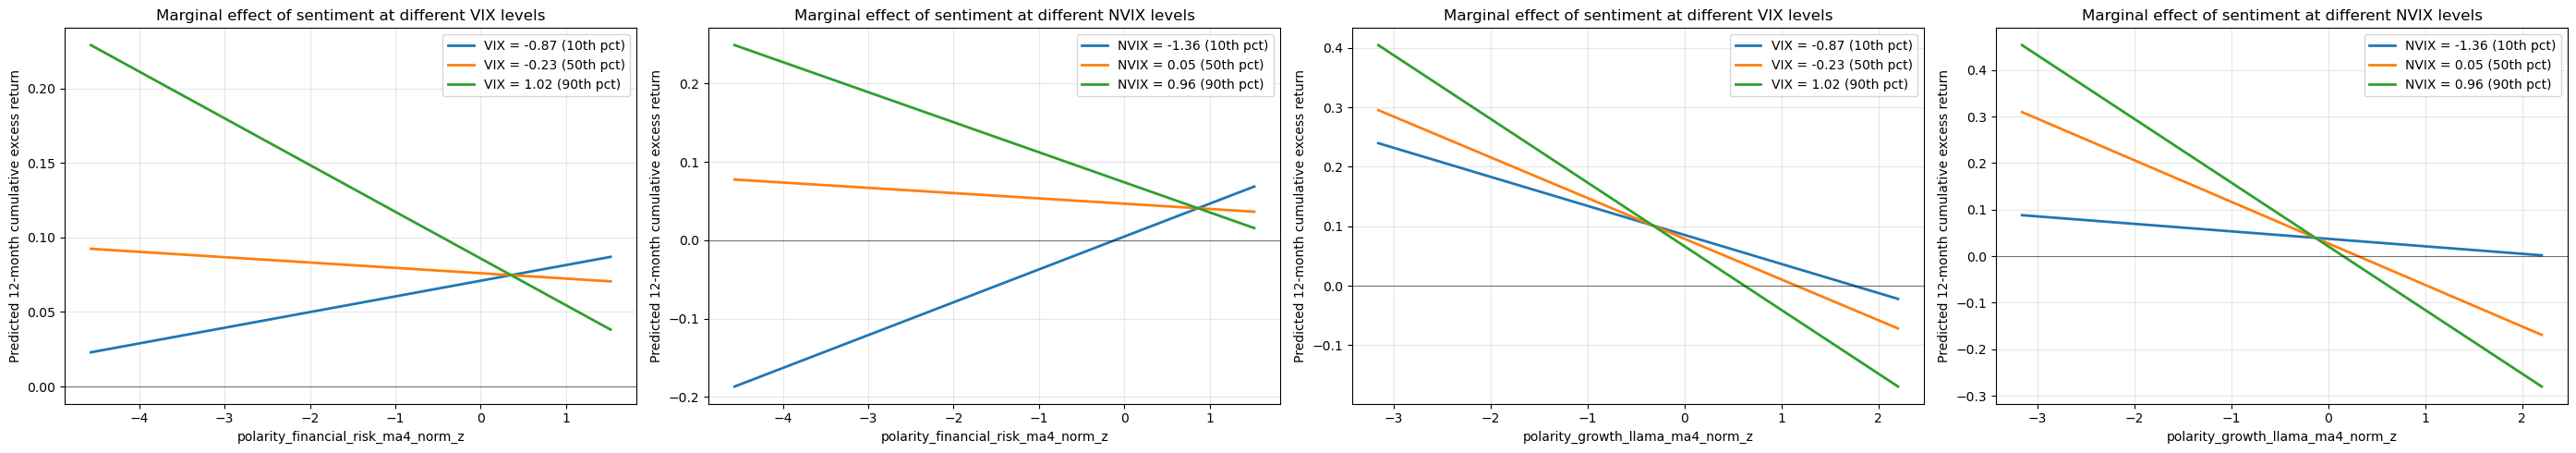

In [17]:
# Marginal effect at the 10th, 50th and 90th percentile of the moderator.
# Percentiles come from the regression's own sample, so the plotted range is the
# range the coefficients were estimated on.
PLOT_HORIZON = 12

pairs = [k for k in interaction_models if k[1] in ("VIX", "NVIX")]
if pairs:
    fig, axes = plt.subplots(1, len(pairs), figsize=(7 * len(pairs), 5), squeeze=False)
    for ax, (measure, label) in zip(axes[0], pairs):
        results = interaction_models[(measure, label)][PLOT_HORIZON]
        predictor = SENTIMENT_Z[measure]
        moderator = MODERATORS[label]
        effects = ec.marginal_effect(results, predictor, moderator, f"{predictor}_x_{moderator}")
        ec.plot_marginal_effect(
            effects, predictor, label,
            ylabel=f"Predicted {PLOT_HORIZON}-month cumulative excess return", ax=ax,
        )
    plt.tight_layout()
    plt.show()